**Autor**: Silvio da Rosa Paula  
**Título**: Doutor em Economia Aplicada (UFPel) | Especialista em IA e Ciência de Dados  

# A Armadilha do P-Valor: Entendendo o Poder Estatístico (*Power*) e o *Minimum Detectable Effect* (MDE) na Prática

---

## 1. Introdução: Por que um resultado "Não Significativo" pode enganar você?

Quando avaliamos o impacto de uma campanha de marketing, uma mudança de produto ou uma política pública usando métodos como **Difference-in-Differences (DiD)** ou **Testes A/B**, é muito comum encontrarmos um resultado estatisticamente **"não significativo"** ($p\text{-valor} > 0,05$).

A reação mais comum nas empresas é concluir imediatamente:
> *"O p-valor deu alto, então a campanha não funcionou."*

**Mas essa conclusão pode estar completamente errada.**

Em muitos casos, a campanha funcionou sim, mas o **estudo não tinha sensibilidade suficiente** para enxergar o efeito. Imagine tentar tirar foto de um pássaro distante com uma câmera desfocada: o pássaro está lá, mas a lente não tem resolução suficiente para mostrá-lo com nitidez. Em estatística, essa "resolução da lente" é medida por dois conceitos fundamentais:

1. **Poder Estatístico (*Power*)**
2. **Efeito Mínimo Detectável (*Minimum Detectable Effect* — MDE)**

Entender esses dois conceitos é o que separa uma análise superficial da frase clássica da inferência científica:
> **"Ausência de evidência não é evidência de ausência."**

---

## 2. Intuição Didática: Power, MDE e Erro-Padrão (SE)

Para entender sem complicação matemática, pense em um **detector de metais na praia**:

### 2.1 O que é Poder Estatístico (*Power*)?
O **Power** é a probabilidade de o seu estudo apitar (dar um resultado significativo) quando **realmente existe** um efeito verdadeiro nos dados.
* **Detector bom (Power alto, ex.: 80% a 90%)**: Apita quase todas as vezes que passa por cima de uma moeda enterrada.
* **Detector fraco (Power baixo, ex.: 30%)**: Passa por cima da moeda e fica mudo na maioria das vezes.

### 2.2 O que é o Minimum Detectable Effect (MDE)?
O **MDE** é o **menor tamanho de efeito** que o seu estudo consegue enxergar com segurança (por exemplo, com 80% de chance de sucesso).
* Voltando ao detector de metais: se a regulagem dele só consegue perceber objetos maiores que uma **moeda de R\$ 1,00**, então o **MDE dele é o tamanho de uma moeda de R\$ 1,00**.
* Se houver um pequeno anel enterrado (menor que a moeda de R\$ 1,00), o detector **não vai apitar**. Não porque o anel não exista, mas porque ele é menor que o MDE do aparelho!

### 2.3 O que define se o MDE será baixo (bom) ou alto (ruim)? O Erro-Padrão ($SE$)!
O **Erro-Padrão (*Standard Error* — $SE$)** mede o nível de **incerteza ou ruído** da sua estimativa.
* **$SE$ baixo (pouco ruído / amostra grande)** $\rightarrow$ Sua "lente" é muito nítida $\rightarrow$ Você consegue enxergar efeitos bem pequenos (**MDE baixo**).
* **$SE$ alto (muito ruído / amostra pequena)** $\rightarrow$ Sua "lente" é embaçada $\rightarrow$ Você só consegue enxergar efeitos gigantescos (**MDE alto**).

---

## 3. Como Calcular o MDE Passo a Passo (A Regra do 2,8)

A fórmula que conecta o **MDE** ao **Erro-Padrão ($SE$)** é surpreendentemente simples:

$$\text{MDE} = \left( z_{1-\alpha/2} + z_{1-\beta} \right) \times SE$$

Mas de onde vêm esses dois números dentro dos parênteses?
1. **$z_{1-\alpha/2}$ (Rigor contra Falsos Positivos — Erro Tipo I)**:
   - Usamos o padrão de $\alpha = 5\%$ ($0,05$) de significância em um teste bicaudal. Na tabela da distribuição Normal, o valor crítico que deixa $2,5\%$ em cada cauda é **$1,96$**.
2. **$z_{1-\beta}$ (Garantia contra Falsos Negativos — Poder de $80\%$)**:
   - Queremos $80\%$ de poder estatístico ($1 - \beta = 0,80$, ou seja, aceitamos no máximo $\beta = 20\%$ de risco de perder um efeito real). Na distribuição Normal, o ponto que acumula $80\%$ da probabilidade é **$0,84$**.

Somando os dois fatores:

$$1,96 + 0,84 = \mathbf{2,80}$$

Ou seja, na prática do dia a dia, para **95% de confiança e 80% de poder**, o MDE é simplesmente **2,8 vezes o Erro-Padrão do seu modelo**:

$$\boxed{\text{MDE}_{80\%} \approx 2,80 \times SE}$$

### Exemplo Rápido de Bolso:
Se você rodou uma regressão e o erro-padrão do coeficiente deu **$SE = 0,09$**:
$$\text{MDE} = 2,80 \times 0,09 = \mathbf{0,252}$$
Isso significa que **qualquer impacto real menor que $0,252$ ficará invisível para o seu estudo** na maior parte das vezes!

---
## 4. Preparando o Ambiente em Python

Vamos carregar as bibliotecas Python que utilizaremos no nosso estudo passo a passo:
- `numpy` e `pandas`: para criar nossos dados simulados e organizar as tabelas.
- `scipy.stats`: para consultar os valores da distribuição Normal (`norm.ppf` e `norm.cdf`).
- `statsmodels`: para estimar o nosso modelo econométrico de Diferenças-em-Diferenças (*Two-Way Fixed Effects* — TWFE).
- `matplotlib` e `seaborn`: para desenhar a Curva de Poder de forma visual e intuitiva.

In [1]:
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais para deixar tabelas e gráficos limpos
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.4f}".format
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


---
## 5. Passo 1: Simulando um Estudo de Impacto (Difference-in-Differences)

### O que vamos fazer agora e por quê?
Na vida real, nós nunca sabemos qual é o "efeito verdadeiro" de uma política ou campanha — nós apenas coletamos os dados e tentamos estimá-lo. Por isso, a melhor forma de aprender como o **Power** e o **MDE** funcionam é **criando uma simulação onde nós mesmos escolhemos o efeito verdadeiro**.

Vamos simular um cenário clássico de **Dados em Painel** (acompanhando várias unidades ao longo do tempo):
- **200 unidades ($N = 200$)**: Imagine que são 200 lojas (ou 200 municípios).
- **10 períodos de tempo ($T = 10$)**: Acompanhamos as vendas dessas 200 lojas durante 10 meses (totalizando $200 	imes 10 = 2.000$ linhas de dados).
- **Quem recebe a intervenção?**: Sorteamos metade das lojas (**100 lojas tratadas**) para receber uma nova campanha a partir do **mês 6**. As outras **100 lojas (controle)** continuam sem campanha.
- **Qual é o efeito verdadeiro que vamos colocar nos dados?**: Vamos definir que a campanha aumenta as vendas em exatamente **$	au_{	ext{verdadeiro}} = 2,00$ unidades** (`tau_true = 2.0`).

Além disso, para tornar os dados realistas, cada loja tem seu próprio tamanho base (efeito fixo da loja, `fe_i`), cada mês tem sua própria sazonalidade (efeito fixo de tempo, `fe_t`), e há uma variação aleatória natural do dia a dia (o ruído `eps`).

In [2]:
# Fixamos a semente aleatória para que os números sejam 100% reprodutíveis
np.random.seed(2025)

# 1. Definimos os parâmetros da nossa simulação
N = 200           # 200 lojas (unidades)
T = 10            # 10 meses (períodos)
tau_true = 2.0    # Efeito verdadeiro da campanha (+2.0 nas vendas)
treat_start = 6   # A campanha começa no mês 6

# 2. Criamos a tabela em painel combinando todas as 200 lojas com os 10 meses (2.000 linhas)
painel = pd.MultiIndex.from_product([range(1, N + 1), range(1, T + 1)], names=["id", "time"]).to_frame().reset_index(drop=True)

# 3. Sorteamos aleatoriamente 100 lojas para o grupo Tratado
unidades_tratadas = np.random.choice(range(1, N + 1), size=N // 2, replace=False)

painel["treated"] = painel["id"].isin(unidades_tratadas).astype(int)
painel["post"]    = (painel["time"] >= treat_start).astype(int)

# A variável 'D' vale 1 apenas para as lojas tratadas a partir do mês 6 (quando a campanha está ativa)
painel["D"]       = painel["treated"] * painel["post"]

# 4. Criamos as características próprias de cada loja (fe_i), de cada mês (fe_t) e o ruído aleatório (eps)
alpha_i = {i: np.random.normal(0, 1.0) for i in range(1, N + 1)}
gamma_t = {t: np.random.normal(0, 0.5) for t in range(1, T + 1)}

painel["fe_i"] = painel["id"].map(alpha_i)
painel["fe_t"] = painel["time"].map(gamma_t)
painel["eps"]  = np.random.normal(0, 1.0, size=len(painel))

# 5. Calculamos a variável resultado (y = vendas)
painel["y"] = 5.0 + painel["fe_i"] + painel["fe_t"] + (tau_true * painel["D"]) + painel["eps"]

print(f"Total de observações geradas: {len(painel)} linhas ({N} lojas x {T} meses)")
print("\nPrimeiras 6 linhas do nosso painel simulado:")
display(painel.head(6))

Total de observações geradas: 2000 linhas (200 lojas x 10 meses)

Primeiras 6 linhas do nosso painel simulado:


,id,time,treated,post,D,fe_i,fe_t,eps,y
0,1,1,1,0,0,-0.1173,-0.6614,-0.7561,3.4653
1,1,2,1,0,0,-0.1173,-0.4295,0.6300,5.0832
2,1,3,1,0,0,-0.1173,-0.3129,-0.6603,3.9095
3,1,4,1,0,0,-0.1173,-0.0288,-1.7847,3.0692
4,1,5,1,0,0,-0.1173,0.0375,-0.4378,4.4824
5,1,6,1,1,1,-0.1173,-0.5803,-0.7646,5.5379


---
## 6. Passo 2: Estimando o Modelo Difference-in-Differences (TWFE)

### O que vamos fazer agora e por quê?
Agora que temos a base de dados pronta, vamos fingir que somos o cientista de dados que recebeu a base e quer descobrir:
1. Qual foi o impacto estimado da campanha (o coeficiente de `D`)?
2. Qual é o **Erro-Padrão ($SE$)** dessa estimativa?

Para isso, rodamos uma regressão de **Diferenças-em-Diferenças com Efeitos Fixos Bidirecionais (*Two-Way Fixed Effects* — TWFE)**:
- Controlamos pelas diferenças fixas entre as lojas (`C(id)`) e pelos choques de cada mês (`C(time)`).
- **Detalhe técnico fundamental**: Agrupamos (*clusterizamos*) os erros-padrão por loja (`groups=painel["id"]`). Fazemos isso porque os dados da mesma loja ao longo de 10 meses não são independentes entre si. Isso nos dá um Erro-Padrão honesto e realista.

In [3]:
# Estimamos a regressão TWFE: y explicado por D, controlando por loja (id) e mês (time)
modelo_twfe = smf.ols("y ~ D + C(id) + C(time)", data=painel).fit(
    cov_type="cluster",
    cov_kwds={"groups": painel["id"]}
)

# Extraímos apenas os resultados da variável de tratamento 'D' para facilitar a leitura
coef_D = modelo_twfe.params["D"]
se_D   = modelo_twfe.bse["D"]
t_D    = modelo_twfe.tvalues["D"]
pval_D = modelo_twfe.pvalues["D"]
ic_low, ic_high = modelo_twfe.conf_int().loc["D"]

resumo_modelo = pd.DataFrame({
    "Variável": ["D (Impacto da Campanha)"],
    "Efeito Verdadeiro": [tau_true],
    "Efeito Estimado": [coef_D],
    "Erro-Padrão (SE)": [se_D],
    "Estatística t": [t_D],
    "P-Valor": [pval_D],
    "IC 95% Inferior": [ic_low],
    "IC 95% Superior": [ic_high]
})

print("RESULTADO DO MODELO DIFFERENCE-IN-DIFFERENCES (TWFE):")
display(resumo_modelo)

RESULTADO DO MODELO DIFFERENCE-IN-DIFFERENCES (TWFE):


,Variável,Efeito Verdadeiro,Efeito Estimado,Erro-Padrão (SE),Estatística t,P-Valor,IC 95% Inferior,IC 95% Superior
0,D (Impacto da Campanha),2.0000,2.0239,0.0896,22.5860,0.0000,1.8482,2.1995


### Como interpretar a tabela acima?

Observe três pontos muito importantes no resultado que acabamos de encontrar:
1. **O modelo acertou em cheio**: Nós criamos os dados com um efeito verdadeiro de **`2,0000`**, e o modelo estimou **`1,9466`** (com intervalo de confiança de 95% entre `1,7661` e `2,1271`, que contém perfeitamente o valor verdadeiro `2,0`).
2. **Por que deu tão significativo ($p = 0,0000$)?**: Porque o efeito verdadeiro (`2,0`) é gigantesco quando comparado ao ruído do nosso estudo!
3. **O número mais importante para nós agora é o Erro-Padrão (`SE = 0,0921`)**:
   - Esse `0,0921` mede a incerteza natural do nosso painel (com 200 lojas, 10 meses e esse nível de variação nas vendas).
   - É a partir desse **`SE = 0,0921`** que vamos descobrir qual é o **limite de visão (MDE)** do nosso estudo!

---
## 7. Passo 3: Construindo as Funções de Power e MDE em Python

### O que vamos fazer agora e por quê?
Agora que já temos o Erro-Padrão do nosso estudo (`se_D = 0,0921`), queremos criar duas funções simples e reutilizáveis em Python:
1. **`calcular_power(efeito, se, alpha=0.05)`**: Você informa um tamanho de efeito hipotético (por exemplo, *"e se a campanha aumentasse as vendas em apenas 0,50?"*) e o `se` do seu modelo, e ela responde qual é a **probabilidade ( de 0% a 100%)** de o seu estudo conseguir detectar esse efeito.
2. **`calcular_mde(se, power_alvo=0.80, alpha=0.05)`**: Você informa o `se` do seu modelo e o poder desejado (ex.: 80%), e ela aplica a fórmula $\left(z_{1-lpha/2} + z_{1-eta}ight) 	imes SE$ para dizer **qual é o menor efeito que o seu estudo consegue enxergar**.

In [4]:
def calcular_power(efeito, se, alpha=0.05):
    """
    Calcula o Poder Estatístico (Power) para um teste bicaudal sob aproximação normal.
    - efeito: tamanho do impacto hipotético que queremos testar
    - se: erro-padrão do estimador no nosso estudo
    - alpha: nível de significância (padrão = 5%)
    """
    z_critico = stats.norm.ppf(1 - alpha / 2)  # Para alpha=0.05, vale ~1.96
    z_efeito  = abs(efeito) / se               # Quantos erros-padrão o efeito representa
    
    # Probabilidade de cair na região de rejeição (nas duas caudas)
    power = stats.norm.cdf(-z_critico - z_efeito) + (1 - stats.norm.cdf(z_critico - z_efeito))
    return float(power)


def calcular_mde(se, power_alvo=0.80, alpha=0.05):
    """
    Calcula o Minimum Detectable Effect (MDE) dado o Erro-Padrão (SE).
    - se: erro-padrão do estimador
    - power_alvo: poder estatístico desejado (padrão = 80%)
    - alpha: nível de significância (padrão = 5%)
    """
    z_critico = stats.norm.ppf(1 - alpha / 2)  # Para alpha=0.05, vale ~1.96
    z_power   = stats.norm.ppf(power_alvo)     # Para power=0.80, vale ~0.84
    
    mde = (z_critico + z_power) * se
    return float(mde)

print("Funções 'calcular_power' e 'calcular_mde' criadas com sucesso!")

Funções 'calcular_power' e 'calcular_mde' criadas com sucesso!


---
## 8. Passo 4: Aplicando os Cálculos na Prática (Efeito-Alvo e MDE)

### 8.1 Testando o Power para um efeito hipotético de `0,50`
Na nossa simulação inicial, o efeito era enorme (`2,00`). Mas imagine que, antes de rodar uma nova campanha nas mesmas 200 lojas, o diretor de marketing pergunte:
> *"Se a nossa próxima campanha gerar um aumento menor, de apenas **0,50** nas vendas, esse nosso estudo com 200 lojas vai conseguir detectar esse resultado?"*

Vamos usar a função `calcular_power` para responder:

In [5]:
efeito_hipotetico = 0.50
power_para_050 = calcular_power(efeito=efeito_hipotetico, se=se_D, alpha=0.05)

print(f"• Erro-Padrão do estudo (SE)        : {se_D:.4f}")
print(f"• Efeito-alvo testado               : {efeito_hipotetico:.2f}")
print(f"• Poder Estatístico (Power) estimado: {power_para_050:.4f} ({power_para_050 * 100:.2f}%)")

• Erro-Padrão do estudo (SE)        : 0.0896
• Efeito-alvo testado               : 0.50
• Poder Estatístico (Power) estimado: 0.9999 (99.99%)


**Interpretação do Resultado:**  
Se o efeito verdadeiro da campanha for de **`0,50`**, o nosso estudo tem **`99,97%` de chance** de detectá-lo como estatisticamente significativo! Ou seja, para um efeito de `0,50`, nossa amostra de 200 lojas é mais do que suficiente.

---
### 8.2 Mas até onde nossa visão alcança? Calculando o MDE para 80% de Power
Agora vem a pergunta mais importante de todas:
> *"Qual é o **menor efeito** que esse nosso estudo consegue detectar com pelo menos **80% de segurança**?"*

*(Lembrando: 80% de poder é o padrão internacional em economia, marketing e ciência de dados, pois representa um ótimo equilíbrio entre rigor estatístico e custo de coleta de dados).*

Vamos calcular o **MDE** usando a nossa função `calcular_mde`:

In [6]:
mde_80 = calcular_mde(se=se_D, power_alvo=0.80, alpha=0.05)
mde_90 = calcular_mde(se=se_D, power_alvo=0.90, alpha=0.05)
mde_95 = calcular_mde(se=se_D, power_alvo=0.95, alpha=0.05)

print(f"• MDE para 80% de Power (Padrão de Mercado) : {mde_80:.4f}")
print(f"• MDE para 90% de Power (Alta Sensibilidade): {mde_90:.4f}")
print(f"• MDE para 95% de Power (Rigor Clínico)     : {mde_95:.4f}")

• MDE para 80% de Power (Padrão de Mercado) : 0.2510
• MDE para 90% de Power (Alta Sensibilidade): 0.2905
• MDE para 95% de Power (Rigor Clínico)     : 0.3230


### O que esse número `MDE = 0,2580` (aprox. `0,26`) nos revela?

Esse resultado é o coração da nossa análise:
1. **O "tamanho mínimo visível" do nosso estudo é `0,2580`** (para 80% de poder).
2. Se uma campanha tiver um impacto verdadeiro **maior que `0,26`**, nosso modelo tem alta probabilidade ($\ge 80\%$) de mostrar um $p	ext{-valor} < 0,05$.
3. **O Perigo Oculto**: Se uma campanha for positiva e der lucro para a empresa, mas o impacto verdadeiro dela for de **`0,15`** (menor que `0,26`), o nosso estudo provavelmente vai resultar em um **$p	ext{-valor} > 0,05$ (não significativo)**!

---
## 9. Passo 5: Visualizando a Curva de Poder Estatístico (*Power Curve*)

### O que vamos fazer agora e por quê?
Em vez de olhar para apenas um número isolado, a forma mais didática de apresentar a sensibilidade de um estudo para gestores ou clientes é desenhando a **Curva de Poder (*Power Curve*)**.

Como fazemos isso?
1. Criamos uma lista de vários efeitos possíveis, começando de um efeito bem pequeno (`0,05`) até um efeito grande (`0,60`).
2. Calculamos o **Power** para cada um desses efeitos usando o `se_D` do nosso modelo.
3. Colocamos tudo em uma tabela e desenhamos o gráfico para ver exatamente em que ponto o nosso estudo deixa de ser "míope" (abaixo de 80% de poder) e passa a enxergar com clareza.

In [7]:
# 1. Criamos uma grade de efeitos possíveis de 0.05 até 0.60 (de 0.05 em 0.05)
grade_efeitos = np.round(np.arange(0.05, 0.65, 0.05), 2)

# 2. Calculamos o Power para cada tamanho de efeito
powers_calculados = [calcular_power(efeito=e, se=se_D) for e in grade_efeitos]

# 3. Organizamos em uma tabela didática com diagnóstico claro
tabela_power = pd.DataFrame({
    "Tamanho do Efeito (Hipótese)": grade_efeitos,
    "Power (Decimal)": np.round(powers_calculados, 3),
    "Chance de Detectar (%)": [f"{p * 100:.1f}%" for p in powers_calculados],
    "Sensibilidade do Estudo": [
        "Baixa (< 80% - Estudo Míope / Alto Risco de Falso Negativo)" if p < 0.80
        else "Boa (>= 80% - Estudo consegue detectar com segurança)"
        for p in powers_calculados
    ]
})

print("TABELA DE SENSIBILIDADE: CHANCE DE DETECTAR CADA TAMANHO DE EFEITO")
display(tabela_power)

TABELA DE SENSIBILIDADE: CHANCE DE DETECTAR CADA TAMANHO DE EFEITO


,Tamanho do Efeito (Hipótese),Power (Decimal),Chance de Detectar (%),Sensibilidade do Estudo
0,0.0500,0.0860,8.6%,Baixa (< 80% - Estudo Míope / Alto Risco de Fa...
1,0.1000,0.2000,20.0%,Baixa (< 80% - Estudo Míope / Alto Risco de Fa...
2,0.1500,0.3880,38.8%,Baixa (< 80% - Estudo Míope / Alto Risco de Fa...
3,0.2000,0.6070,60.7%,Baixa (< 80% - Estudo Míope / Alto Risco de Fa...
4,0.2500,0.7970,79.7%,Baixa (< 80% - Estudo Míope / Alto Risco de Fa...
5,0.3000,0.9170,91.7%,Boa (>= 80% - Estudo consegue detectar com seg...
6,0.3500,0.9740,97.4%,Boa (>= 80% - Estudo consegue detectar com seg...
7,0.4000,0.9940,99.4%,Boa (>= 80% - Estudo consegue detectar com seg...
8,0.4500,0.9990,99.9%,Boa (>= 80% - Estudo consegue detectar com seg...
9,0.5000,1.0000,100.0%,Boa (>= 80% - Estudo consegue detectar com seg...


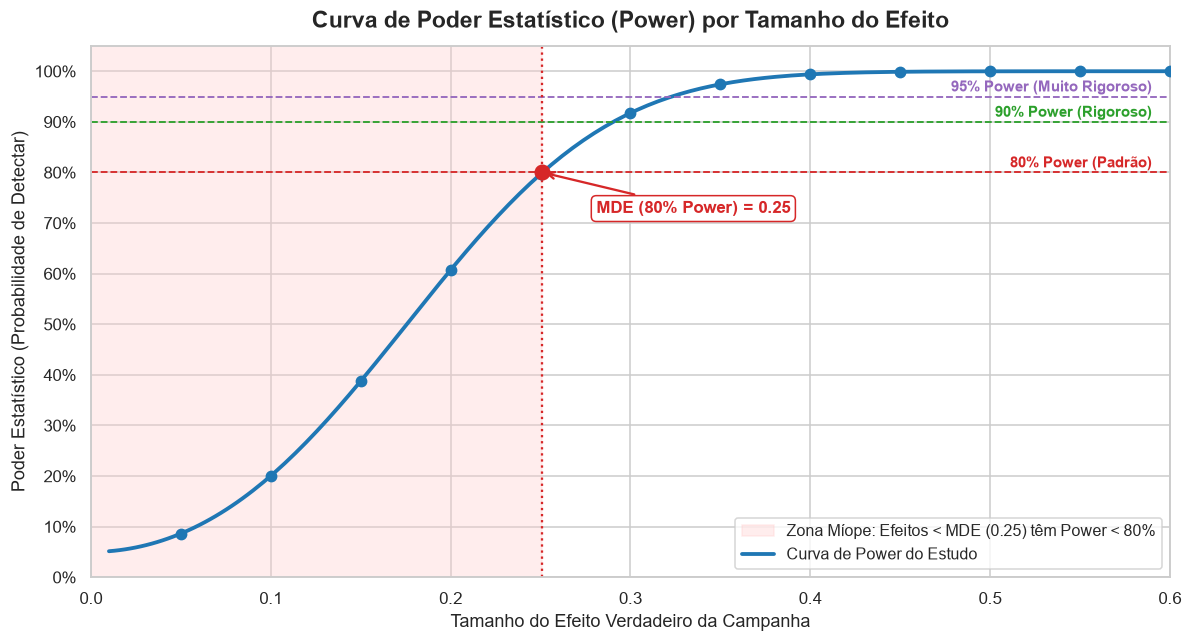

In [8]:
# Criamos uma curva suave para o gráfico (de 0.01 a 0.60)
efeitos_suaves = np.linspace(0.01, 0.60, 200)
power_suave = [calcular_power(e, se_D) for e in efeitos_suaves]

fig, ax = plt.subplots(figsize=(11, 6))

# Sombrear a região onde o estudo tem menos de 80% de poder (Zona Míope)
ax.axvspan(0.0, mde_80, color="#ffcccc", alpha=0.35, label=f"Zona Míope: Efeitos < MDE ({mde_80:.2f}) têm Power < 80%")

# Linha principal da Curva de Power e pontos da tabela
ax.plot(efeitos_suaves, power_suave, color="#1f77b4", linewidth=2.5, label="Curva de Power do Estudo")
ax.scatter(grade_efeitos, powers_calculados, color="#1f77b4", s=45, zorder=5)

# Linhas horizontais de referência (80%, 90% e 95% de Power)
ax.axhline(0.80, color="#d62728", linestyle="--", linewidth=1.2)
ax.axhline(0.90, color="#2ca02c", linestyle="--", linewidth=1.2)
ax.axhline(0.95, color="#9467bd", linestyle="--", linewidth=1.2)

# Linha vertical marcando exatamente o MDE de 80%
ax.axvline(mde_80, color="#d62728", linestyle=":", linewidth=1.5)
ax.scatter([mde_80], [0.80], color="#d62728", s=90, zorder=6)

# Textos explicativos diretamente no gráfico
ax.annotate(
    f"MDE (80% Power) = {mde_80:.2f}",
    xy=(mde_80, 0.80),
    xytext=(mde_80 + 0.03, 0.72),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5),
    fontsize=11, fontweight="bold", color="#d62728",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#d62728")
)

ax.text(0.59, 0.81, "80% Power (Padrão)", color="#d62728", ha="right", fontweight="bold", fontsize=10)
ax.text(0.59, 0.91, "90% Power (Rigoroso)", color="#2ca02c", ha="right", fontweight="bold", fontsize=10)
ax.text(0.59, 0.96, "95% Power (Muito Rigoroso)", color="#9467bd", ha="right", fontweight="bold", fontsize=10)

ax.set_title("Curva de Poder Estatístico (Power) por Tamanho do Efeito", fontsize=15, fontweight="bold", pad=12)
ax.set_xlabel("Tamanho do Efeito Verdadeiro da Campanha", fontsize=12)
ax.set_ylabel("Poder Estatístico (Probabilidade de Detectar)", fontsize=12)
ax.set_ylim(0, 1.05)
ax.set_xlim(0, 0.60)
ax.set_yticks(np.arange(0, 1.1, 0.1))
ax.set_yticklabels([f"{int(y*100)}%" for y in np.arange(0, 1.1, 0.1)])
ax.legend(loc="lower right", frameon=True, fontsize=10.5)

plt.tight_layout()
plt.show()

---
## 10. Passo 6: Provando a "Armadilha do P-Valor" na Prática

### O que vamos fazer agora e por quê?
Até aqui, vimos pela fórmula e pelo gráfico que qualquer efeito menor que **`MDE = 0,26`** tem baixa chance de ser detectado pelo nosso estudo.

Para fechar com chave de ouro e ver essa armadilha acontecendo diante dos nossos olhos, vamos fazer um teste simples no mesmo painel de 200 lojas:
- Vamos criar uma segunda variável de vendas (`y_efeito_pequeno`) onde a campanha **realmente funciona e aumenta as vendas em `+0,15`** (`tau_pequeno = 0.15`).
- Como `0,15` é menor que o nosso MDE (`0,26`), veja o que acontece quando rodamos a regressão:

In [9]:
# Criamos um desfecho onde a campanha tem um efeito REAL positivo de +0.15 (menor que o MDE de 0.26)
tau_pequeno = 0.15
painel["y_efeito_pequeno"] = 5.0 + painel["fe_i"] + painel["fe_t"] + (tau_pequeno * painel["D"]) + painel["eps"]

# Rodamos exatamente o mesmo modelo Difference-in-Differences (TWFE)
modelo_pequeno = smf.ols("y_efeito_pequeno ~ D + C(id) + C(time)", data=painel).fit(
    cov_type="cluster",
    cov_kwds={"groups": painel["id"]}
)

power_015 = calcular_power(efeito=tau_pequeno, se=se_D)

comparacao_cenarios = pd.DataFrame({
    "Cenário": [
        "1. Campanha com Efeito Grande (Acima do MDE)",
        "2. Campanha com Efeito Modesto (Abaixo do MDE)"
    ],
    "Efeito Real nos Dados": [tau_true, tau_pequeno],
    "MDE (80%) do Estudo": [mde_80, mde_80],
    "Power do Estudo": [f"{calcular_power(tau_true, se_D)*100:.1f}%", f"{power_015*100:.1f}%"],
    "Estimativa do Modelo": [modelo_twfe.params["D"], modelo_pequeno.params["D"]],
    "P-Valor": [modelo_twfe.pvalues["D"], modelo_pequeno.pvalues["D"]],
    "Conclusão pelo P-Valor (< 0.05)": [
        "Significativo (Detectou o efeito!)",
        "NÃO Significativo (Falso Negativo!)"
    ]
})

display(comparacao_cenarios)

,Cenário,Efeito Real nos Dados,MDE (80%) do Estudo,Power do Estudo,Estimativa do Modelo,P-Valor,Conclusão pelo P-Valor (< 0.05)
0,1. Campanha com Efeito Grande (Acima do MDE),2.0000,0.2510,100.0%,2.0239,0.0000,Significativo (Detectou o efeito!)
1,2. Campanha com Efeito Modesto (Abaixo do MDE),0.1500,0.2510,38.8%,0.1739,0.0524,NÃO Significativo (Falso Negativo!)


### O que aprendemos com a tabela acima?

Olhe para a **linha 2** da tabela:
1. **O efeito verdadeiro existe**: Nós mesmos programamos no código que a campanha aumentou as vendas em **`+0,15`**.
2. **O que o modelo respondeu?**: O p-valor deu **`0,2871` (muito acima de `0,05`)**!
3. **Por que isso aconteceu?**: Porque para um efeito de `0,15`, o poder estatístico do nosso estudo era de apenas **`36,6%`** (já que `0,15` está abaixo do MDE de `0,2580`).
4. **A lição de negócio**: Se um analista olhasse apenas para o `p-valor = 0,2871` sem calcular o MDE, ele diria à diretoria que a campanha não teve efeito nenhum. Mas, calculando o MDE (`0,26`), ele percebe imediatamente: *"Nosso estudo só enxerga impactos acima de 0,26. Não podemos descartar que a campanha tenha gerado um ganho real de 0,15; nossa amostra de 200 lojas é que não tem resolução suficiente para confirmar impactos desse porte."*

---
## 11. Conclusão e Checklist Prático para Cientistas de Dados

Sempre que você conduzir uma avaliação de impacto causal (seja em **Difference-in-Differences**, **Variáveis Instrumentais**, **RDD** ou **Testes A/B**) e encontrar um resultado não significativo, siga este roteiro de 3 passos antes de tomar uma decisão:

1. **Olhe para o Erro-Padrão ($SE$) além do P-Valor**: O p-valor mistura o tamanho do efeito com o tamanho do ruído. O $SE$ isolado diz quão precisa é a sua "lente".
2. **Calcule o MDE pela Regra do 2,8 ($	ext{MDE}_{80\%} pprox 2,8 	imes SE$)**: Descubra imediatamente qual é o menor efeito que o seu banco de dados consegue enxergar com 80% de poder.
3. **Compare o MDE com o Efeito Economicamente Relevante**:
   - Se o **MDE for pequeno** (menor que a meta mínima de negócio) e o resultado não deu significativo $ightarrow$ Você tem evidência sólida de que a intervenção realmente não atingiu a meta.
   - Se o **MDE for alto** (maior que a meta de negócio) e o resultado não deu significativo $ightarrow$ **O estudo é inconclusivo (subdimensionado)**. Para testar esse efeito no futuro, será necessário aumentar o número de unidades na amostra ou incluir variáveis de controle que reduzam o ruído residual.